# 1 · Chapters 1–3: scope and the three ways to derive equations of motion

Companion to T. G. O'Kane, *High Fidelity Modelling of Motorcycle Dynamics*, PhD thesis, Maynooth University, 2018.

| Thesis | Content | Here |
|---|---|---|
| Ch. 1 | motivation, layout | – |
| Ch. 2 | literature (Whipple, Sharp, Cossalter/Lot, Pacejka) | – |
| Ch. 3 | Newton / Lagrange / Kane on an inverted pendulum | **this notebook**, `okane/pendulum.py` |
| Ch. 4.2–4.4, 4.8 | degrees of freedom, frames, main-frame position | notebook 2, `okane/frames.py`, `okane/kinematics.py` |
| Ch. 4.5–4.7 | force blocks (suspension, chain, drag, rider, crank) | notebook 3, `okane/forces.py` |
| Ch. 4.10–4.11 | Kane's equations, state-space form, output matrix | notebook 4, `okane/symbolic.py`, `okane/model.py` |

Tyre model (Ch. 5) and controllers / Kalman filter (4.12–4.13) are left for later sessions.

## The test system (Fig. 3.2)
A cart *C* (mass $M_C$, viscous friction $d$) carries an inverted pendulum *P* (mass $M_P$, inertia $I_P$, length $L$) with a torsional spring $k$.
Generalised co-ordinates $q_1$ (cart position), $q_2$ (pendulum angle from vertical); generalised speeds $u_r=\dot q_r$ (eq. 3.1 in its simplest form).
The pendulum mass centre is at $x_p=q_1-L\sin q_2,\;y_p=L\cos q_2$.

In [1]:
import sys, pathlib; sys.path.insert(0, str(pathlib.Path.cwd().parent))   # repo root (not needed after `pip install -e .`)
import numpy as np, sympy as sp, matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from okane import pendulum as P
from okane.plotting import use_style, C
use_style(); sp.init_printing()

## Target: equations (3.7)

In [2]:
thesis = P.thesis_eom()
[sp.Eq(e, 0) for e in thesis]

## 3.6 Newton
Free-body equations for pendulum ($x$, $y$) and cart ($x$), eqs. (3.2)–(3.4). The rod force $F_T$ has to be introduced and eliminated again:
(3.2)+(3.4) gives the first equation, $c_2\,$(3.2)$+s_2\,$(3.3) the second.

In [3]:
newton = P.newton()
display(newton)
P.equivalent(newton, thesis)

True

## 3.7 Lagrange
$K=\tfrac12 M_C\dot q_1^2+\tfrac12 M_P v_P^2+\tfrac12 I_P\dot q_2^2$, $U=\tfrac12 k q_2^2+M_P g L c_2$, non-conservative generalised forces
$Q_1=-d\dot q_1+F_C+F_P$, $Q_2=-F_P L c_2$.

In [4]:
lagrange = P.lagrange()
display(lagrange)
P.equivalent(lagrange, thesis)

True

## 3.8 Kane
Velocities are written as linear functions of the generalised speeds; the coefficient vectors are the **partial velocities** (Table 3.2).
Then $F_r+F_r^*=0$ with
$F_r=\sum \mathbf F\cdot\mathbf v_r+\mathbf T\cdot\boldsymbol\omega_r$ and
$F_r^*=-\sum M\,\mathbf a\cdot\mathbf v_r+(\mathbf I\boldsymbol\alpha+\boldsymbol\omega\times\mathbf I\boldsymbol\omega)\cdot\boldsymbol\omega_r$ (eqs. 3.8, 3.9).

In [5]:
kane, table = P.kane()
for r in (1, 2):
    print(f"r={r}:  v_r^C =", list(table[r]["vC"]), "  w_r^P =", list(table[r]["wP"]), "  v_r^P =", list(table[r]["vP"]))
display(kane)
P.equivalent(kane, thesis)

r=1:  v_r^C = [1, 0, 0]   w_r^P = [0, 0, 0]   v_r^P = [1, 0, 0]
r=2:  v_r^C = [0, 0, 0]   w_r^P = [0, 0, 1]   v_r^P = [-L*cos(q2(t)), -L*sin(q2(t)), 0]


True

All three derivations reproduce (3.7). Only Newton needs the constraint force; only Lagrange needs derivatives of a scalar energy function.
Kane's method needs neither and stays in vector form – the reason it is used for the motorcycle (Section 3.9), and the reason the
numeric motorcycle model in `okane/model.py` is nothing more than sums over tables of partial velocities.

## Simulation and a check
With $d=0$ and no external forces the energy $K+U$ must stay constant. (The upright position is stable only if $k>M_PgL$.)

max |E - E0| = 1.0188117016696197e-10 J


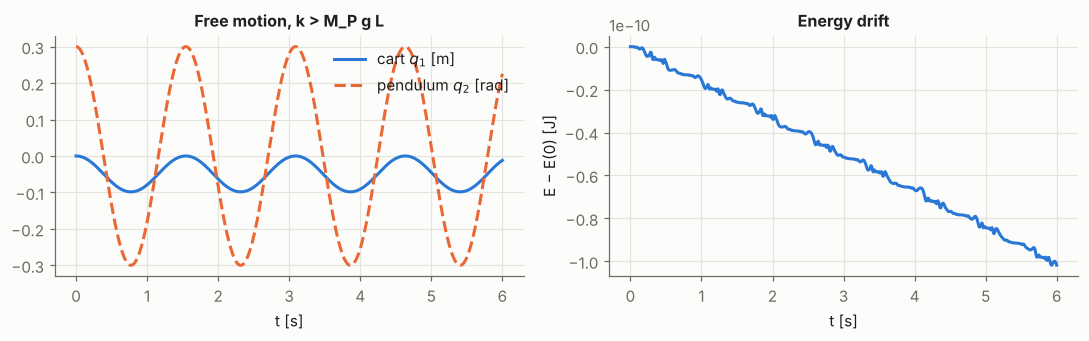

In [6]:
par = {P.MP: 1.0, P.MC: 2.0, P.IP: 0.02, P.L: 0.5, P.k: 8.0, P.d: 0.0, P.g: 9.81}
rhs = P.numeric_rhs(par)
sol = solve_ivp(rhs, (0, 6), [0, 0.3, 0, 0], rtol=1e-10, atol=1e-12, dense_output=True)
t = np.linspace(0, 6, 600); x = sol.sol(t)
MP_, MC_, IP_, L_, k_, g_ = (par[s] for s in (P.MP, P.MC, P.IP, P.L, P.k, P.g))
E = (0.5*MC_*x[2]**2 + 0.5*MP_*(x[2]**2 + L_**2*x[3]**2 - 2*L_*x[2]*x[3]*np.cos(x[1]))
     + 0.5*IP_*x[3]**2 + 0.5*k_*x[1]**2 + MP_*g_*L_*np.cos(x[1]))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(t, x[0], label="cart $q_1$ [m]"); ax[0].plot(t, x[1], "--", label="pendulum $q_2$ [rad]")
ax[0].set_xlabel("t [s]"); ax[0].legend(); ax[0].set_title("Free motion, k > M_P g L")
ax[1].plot(t, E - E[0]); ax[1].set_xlabel("t [s]"); ax[1].set_ylabel("E − E(0) [J]"); ax[1].set_title("Energy drift")
plt.tight_layout()
print("max |E - E0| =", abs(E - E[0]).max(), "J")